In [1]:
import pandas as pd
import numpy as np

DATA_PATH = "../data/raw/cicids_ddos.csv"

df = pd.read_csv(DATA_PATH)

# Clean column names
df.columns = df.columns.str.strip()

print("Shape:", df.shape)
print(df["Label"].value_counts())

Shape: (225745, 79)
Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64


In [2]:
# Replace infinity values with NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Missing values before cleaning:")
print(df.isnull().sum().sum())

Missing values before cleaning:
68


In [3]:
df.dropna(inplace=True)

print("Shape after cleaning:", df.shape)

Shape after cleaning: (225711, 79)


In [4]:
print("Remaining NaN:", df.isnull().sum().sum())
print("Remaining Inf:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())

Remaining NaN: 0
Remaining Inf: 0


In [5]:
for i, column in enumerate(df.columns):
    print(i, column)

0 Destination Port
1 Flow Duration
2 Total Fwd Packets
3 Total Backward Packets
4 Total Length of Fwd Packets
5 Total Length of Bwd Packets
6 Fwd Packet Length Max
7 Fwd Packet Length Min
8 Fwd Packet Length Mean
9 Fwd Packet Length Std
10 Bwd Packet Length Max
11 Bwd Packet Length Min
12 Bwd Packet Length Mean
13 Bwd Packet Length Std
14 Flow Bytes/s
15 Flow Packets/s
16 Flow IAT Mean
17 Flow IAT Std
18 Flow IAT Max
19 Flow IAT Min
20 Fwd IAT Total
21 Fwd IAT Mean
22 Fwd IAT Std
23 Fwd IAT Max
24 Fwd IAT Min
25 Bwd IAT Total
26 Bwd IAT Mean
27 Bwd IAT Std
28 Bwd IAT Max
29 Bwd IAT Min
30 Fwd PSH Flags
31 Bwd PSH Flags
32 Fwd URG Flags
33 Bwd URG Flags
34 Fwd Header Length
35 Bwd Header Length
36 Fwd Packets/s
37 Bwd Packets/s
38 Min Packet Length
39 Max Packet Length
40 Packet Length Mean
41 Packet Length Std
42 Packet Length Variance
43 FIN Flag Count
44 SYN Flag Count
45 RST Flag Count
46 PSH Flag Count
47 ACK Flag Count
48 URG Flag Count
49 CWE Flag Count
50 ECE Flag Count
51 Down/

In [6]:
columns_to_remove = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp"
]

columns_to_remove = [
    col for col in columns_to_remove
    if col in df.columns
]

df.drop(columns=columns_to_remove, inplace=True)

print("Removed:", columns_to_remove)
print("New shape:", df.shape)

Removed: []
New shape: (225711, 79)


In [7]:
df["Label"] = df["Label"].map({
    "BENIGN": 0,
    "DDoS": 1
})

In [8]:
print(df["Label"].value_counts())

Label
1    128025
0     97686
Name: count, dtype: int64


In [9]:
print("Unknown labels:", df["Label"].isna().sum())

Unknown labels: 0


In [10]:
X = df.drop(columns=["Label"])
y = df["Label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (225711, 78)
y shape: (225711,)


In [11]:
non_numeric = X.select_dtypes(exclude=np.number).columns

print("Non-numeric columns:")
print(non_numeric.tolist())

Non-numeric columns:
[]


In [12]:
print(X[non_numeric].head())

Empty DataFrame
Columns: []
Index: [0, 1, 2, 3, 4]


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (180568, 78)
Testing: (45143, 78)


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
scaler.fit_transform(X_train)

array([[-0.4451106 , -0.51086992, -0.12056838, ..., -0.28352491,
        -0.47888119, -0.39138596],
       [-0.4451106 , -0.19423396,  0.07214295, ..., -0.28352491,
        -0.10396056,  0.11766207],
       [-0.44647818, -0.51571054, -0.18480549, ..., -0.28352491,
        -0.47888119, -0.39138596],
       ...,
       [-0.44647818, -0.51381607, -0.2490426 , ..., -0.28352491,
        -0.47888119, -0.39138596],
       [-0.4451106 , -0.50267171, -0.12056838, ..., -0.28352491,
        -0.47888119, -0.39138596],
       [-0.44647818, -0.5136807 , -0.18480549, ..., -0.28352491,
        -0.47888119, -0.39138596]], shape=(180568, 78))

In [16]:
scaler.transform(X_test)

array([[-0.4451106 ,  1.79516493,  0.20061717, ...,  3.12268046,
         2.01564022, -0.10788844],
       [-0.4451106 ,  2.02863987,  0.20061717, ...,  3.57684118,
         2.3014708 , -0.12703152],
       [ 2.86282059,  2.06493388,  0.00790584, ..., -0.28352491,
         2.50934758,  3.66587797],
       ...,
       [-0.4451106 , -0.31142445, -0.05633127, ..., -0.28352491,
        -0.23990277, -0.0669133 ],
       [-0.44647818, -0.50879008, -0.2490426 , ..., -0.28352491,
        -0.47888119, -0.39138596],
       [-0.4451106 , -0.48631816, -0.12056838, ..., -0.28352491,
        -0.47888119, -0.39138596]], shape=(45143, 78))

In [17]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [18]:
y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.9999
Precision: 0.9999
Recall   : 0.9999
F1 Score : 0.9999
ROC-AUC  : 1.0000


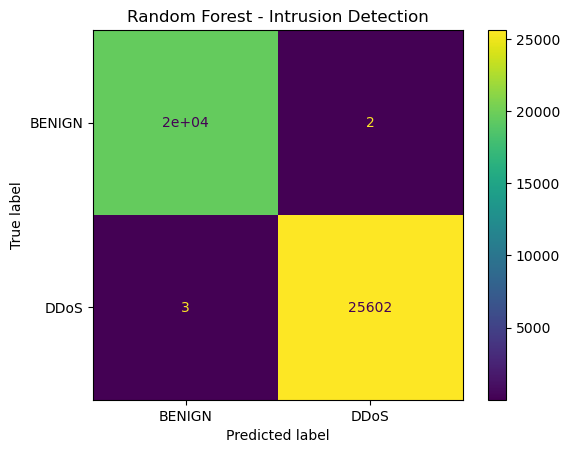

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "DDoS"]
)

disp.plot()

plt.title("Random Forest - Intrusion Detection")
plt.show()

In [21]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["BENIGN", "DDoS"]
    )
)

              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19538
        DDoS       1.00      1.00      1.00     25605

    accuracy                           1.00     45143
   macro avg       1.00      1.00      1.00     45143
weighted avg       1.00      1.00      1.00     45143



In [22]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
6,Fwd Packet Length Max,0.078187
66,Init_Win_bytes_forward,0.075847
8,Fwd Packet Length Mean,0.073031
53,Avg Fwd Segment Size,0.072411
62,Subflow Fwd Packets,0.056870
63,Subflow Fwd Bytes,0.056317
4,Total Length of Fwd Packets,0.049913
11,Bwd Packet Length Min,0.047531
0,Destination Port,0.045059
68,act_data_pkt_fwd,0.039250


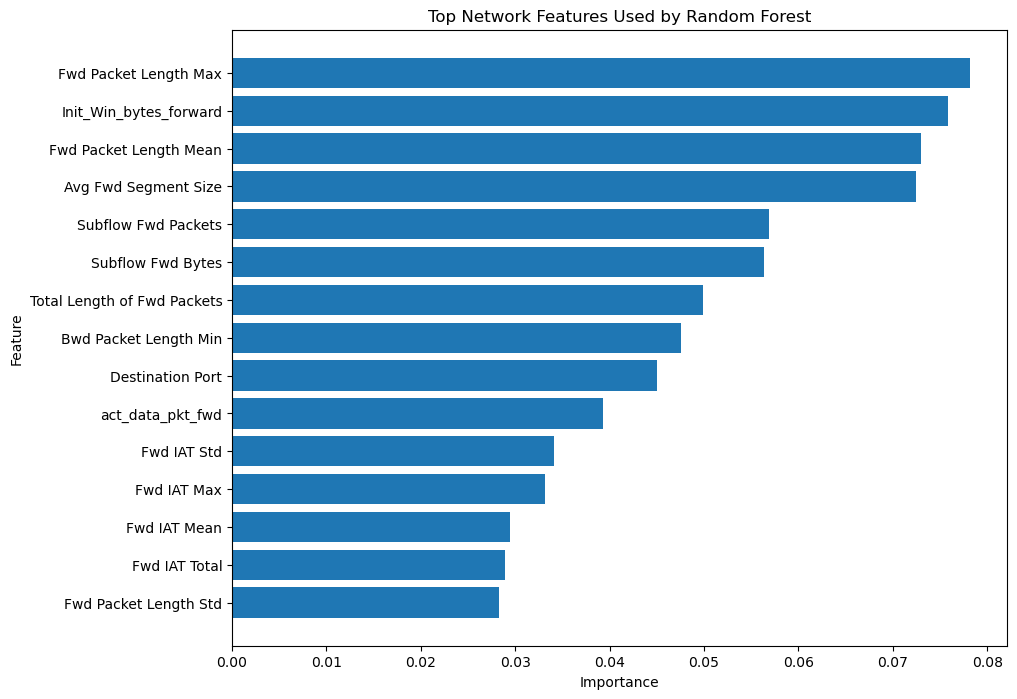

In [23]:
plt.figure(figsize=(10, 8))

top_features = feature_importance.head(15)

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Network Features Used by Random Forest")

plt.show()

In [24]:
import joblib

joblib.dump(model, "../models/random_forest_ids.pkl")
joblib.dump(scaler, "../models/scaler.pkl")

print("Model saved successfully.")

Model saved successfully.
